In [58]:
#Project 1: Titanic Survival Analysis

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [60]:
test_df=pd.read_csv(r"tested.csv")

In [61]:
test_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [62]:
test_df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


In [63]:
test_df.info

<bound method DataFrame.info of      PassengerId  Survived  Pclass  \
0            892         0       3   
1            893         1       3   
2            894         0       2   
3            895         0       3   
4            896         1       3   
..           ...       ...     ...   
413         1305         0       3   
414         1306         1       1   
415         1307         0       3   
416         1308         0       3   
417         1309         0       3   

                                             Name     Sex   Age  SibSp  Parch  \
0                                Kelly, Mr. James    male  34.5      0      0   
1                Wilkes, Mrs. James (Ellen Needs)  female  47.0      1      0   
2                       Myles, Mr. Thomas Francis    male  62.0      0      0   
3                                Wirz, Mr. Albert    male  27.0      0      0   
4    Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female  22.0      1      1   
..                       

In [64]:
test_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [65]:
test_df['Age'].isnull().sum()

np.int64(86)

In [66]:
test_df['Age'].median()

np.float64(27.0)

In [67]:
test_df['Age']=test_df['Age'].fillna(test_df['Age'].median())

In [68]:
test_df['Age'].isnull().sum()

np.int64(0)

In [69]:
test_df['Fare'].isnull().sum()

np.int64(1)

In [70]:
test_df['Fare'].median()

np.float64(14.4542)

In [71]:
test_df['Fare']=test_df['Fare'].fillna(test_df['Fare'].median())

In [72]:
test_df['Fare'].isnull().sum()

np.int64(0)

In [73]:
test_df['Cabin'].isnull().sum()

np.int64(327)

In [74]:
test_df['Cabin']=test_df['Cabin'].fillna('Unknown')

In [75]:
test_df['Cabin'].isnull().sum()

np.int64(0)

Next task — check duplicate records
Now let's check whether your dataset contains duplicate rows.

Your task: Find the total number of duplicate rows in test_df.

In [76]:
test_df.duplicated().sum()

np.int64(0)

Next: Titanic Exploratory Data Analysis (EDA)
#Task 1 — Survival analysis
#Find how many passengers:
#- Survived (Survived = 1)
#- Did not survive (Survived = 0)

In [77]:
test_df['Survived'].value_counts()

Survived
0    266
1    152
Name: count, dtype: int64

— calculate survival percentage
Calculate the percentage of passengers who survived and did not survive.

Hint: Use the counts divided by the total number of passengers, multiplied by 100.

In [78]:
test_df['Survived'].value_counts()/len(test_df)*100

Survived
0    63.636364
1    36.363636
Name: count, dtype: float64

— survival by gender
Find how many male and female passengers survived.

Use groupby() with the Sex and Survived columns.

In [79]:
test_df.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           152
male    0           266
Name: count, dtype: int64

— survival by passenger class
Find the survival counts for each passenger class (Pclass).

In [80]:
test_df.groupby('Pclass')['Survived'].value_counts()

Pclass  Survived
1       0            57
        1            50
2       0            63
        1            30
3       0           146
        1            72
Name: count, dtype: int64

survival percentage by class
Calculate the survival percentage for each passenger class.

Hint: Use groupby('Pclass') and calculate the mean of Survived. Remember that Survived contains 1 for survived and 0 for not survived.

In [81]:
test_df.groupby('Pclass')['Survived'].mean()*100

Pclass
1    46.728972
2    32.258065
3    33.027523
Name: Survived, dtype: float64

Age analysis
Find the average age of passengers in your Titanic dataset.

In [82]:
test_df['Age'].mean()

np.float64(29.599282296650717)

— average age by survival status
Find the average age separately for:
- Passengers who did not survive (0)
- Passengers who survived (1)

In [83]:
test_df.groupby('Survived')['Age'].mean()

Survived
0    29.522218
1    29.734145
Name: Age, dtype: float64

In [84]:
test_df['Fare'].mean()

np.float64(35.57653540669856)

— average fare by survival status
Find the average fare separately for:
- Passengers who did not survive (0)
- Passengers who survived (1)

In [85]:
test_df.groupby('Survived')['Fare'].mean()

Survived
0    27.478728
1    49.747699
Name: Fare, dtype: float64

Seaborn visualization
Task 1 — Survival count plot
Create a Seaborn countplot showing:
- X-axis: Survived
- Y-axis: passenger count
- Title: Titanic Survival Count
Use your existing test_df DataFrame and Matplotlib.

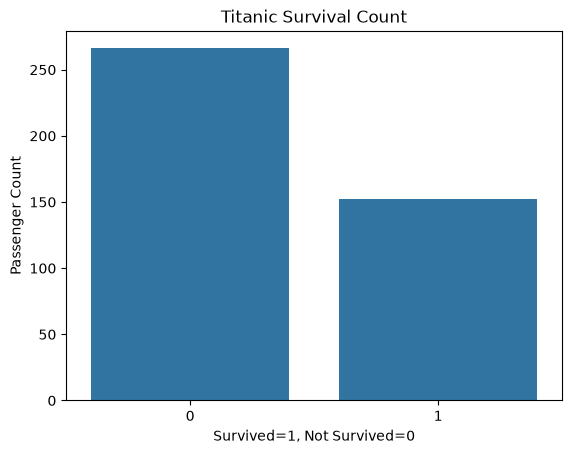

In [86]:
sns.countplot( x='Survived', data=test_df)
plt.title('Titanic Survival Count')
plt.xlabel('Survived=1, Not Survived=0')
plt.ylabel('Passenger Count')
plt.show()

Next task — Survival by gender
Create a count plot showing survival counts by gender.

Requirements:
- X-axis: Sex
- Use hue='Survived' to distinguish survived and not survived.
- Add title: Survival by Gender.
- Display the chart.

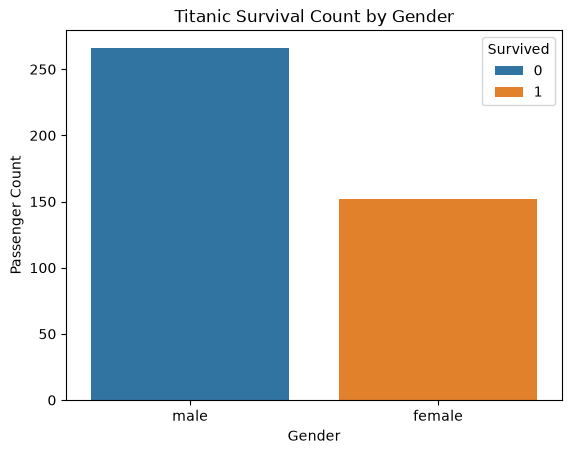

In [87]:
sns.countplot(x='Sex',hue='Survived',data=test_df)
plt.title('Titanic Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Passenger Count')
plt.show()

Next task — Survival by Passenger Class
Create a count plot with:
- X-axis: Pclass
- Hue: Survived
- Title: Survival by Passenger Class
- X-axis label: Passenger Class
- Y-axis label: Passenger Count


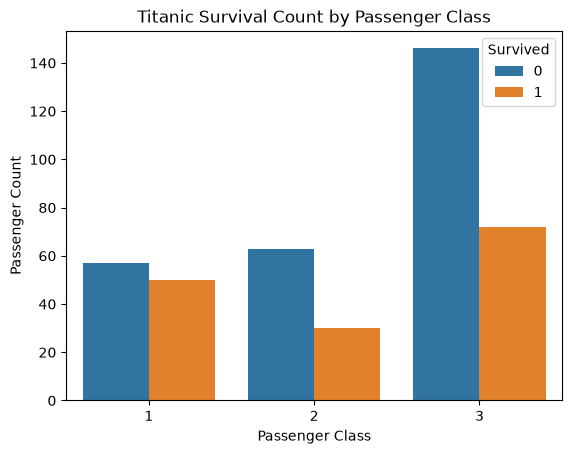

In [88]:
sns.countplot(x='Pclass',hue='Survived',data=test_df)
plt.title('Titanic Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Passenger Count')
plt.show()

Age distribution
Create a histogram to understand the age distribution of Titanic passengers.

Requirements:
- Use sns.histplot()
- Data column: Age
- Use 20 bins.
- Add a KDE curve (kde=True).
- Title: Age Distribution of Titanic Passengers
- X-axis: Age
- Y-axis: Frequency

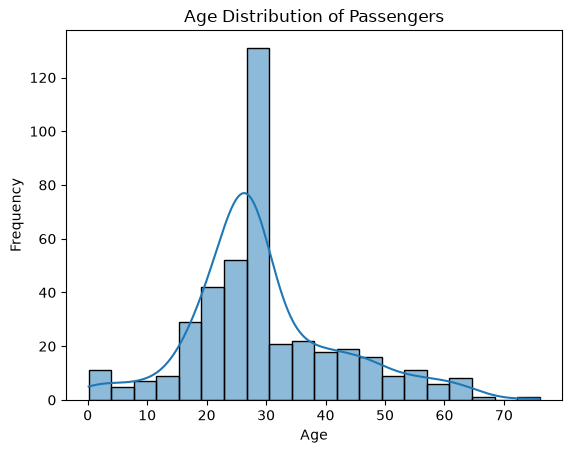

In [89]:
sns.histplot(data=test_df, x='Age', bins=20, kde=True)
plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Fare distribution
Create a histogram to understand ticket fare distribution.

Requirements:
- Use sns.histplot().
- Data: test_df
- Column: Fare
- bins=20
- kde=True
- Title: Fare Distribution of Titanic Passengers
- X-axis: Fare
- Y-axis: Frequency

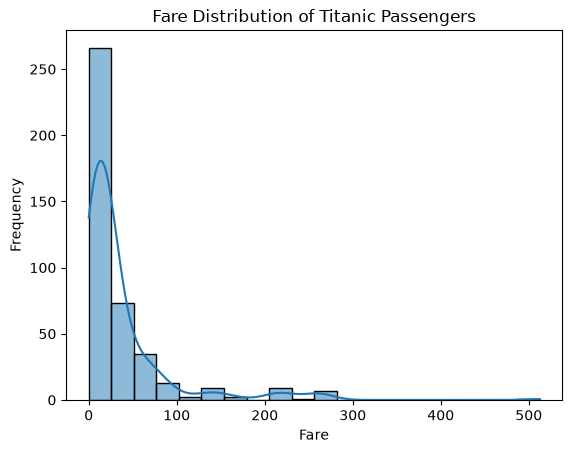

In [90]:
sns.histplot(data=test_df, x='Fare', bins=20, kde=True)
plt.title('Fare Distribution of Titanic Passengers')
plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.show()

Age vs Survival
Create a box plot to compare passenger ages between survivors and non-survivors.

Requirements:
- Use sns.boxplot()
- X-axis: Survived
- Y-axis: Age
- Data: test_df
- Title: Age vs Survival
- X-axis label: Survival Status
- Y-axis label: Age

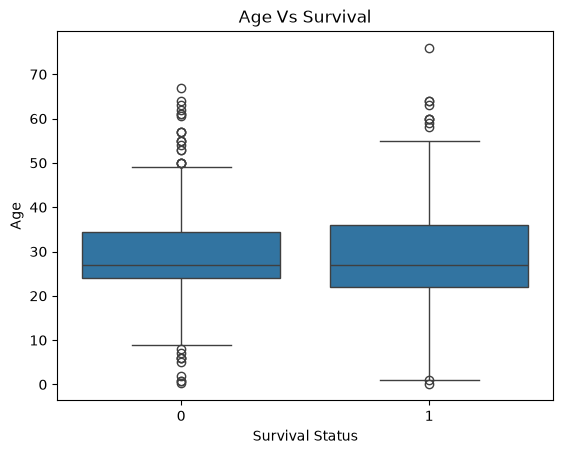

In [91]:
sns.boxplot(x='Survived',y='Age',data=test_df)
plt.title('Age Vs Survival')
plt.xlabel('Survival Status')
plt.ylabel('Age')
plt.show()

Assignment 1 — Business question
Management wants to know:

"What percentage of passengers survived, and what percentage did not survive?"

Your deliverable:
- Calculate both percentages.
- Create a professional pie chart.
- Write one business insight in 2–3 sentences.
Dataset: test_df

Expected output: A chart and a short written conclusion.

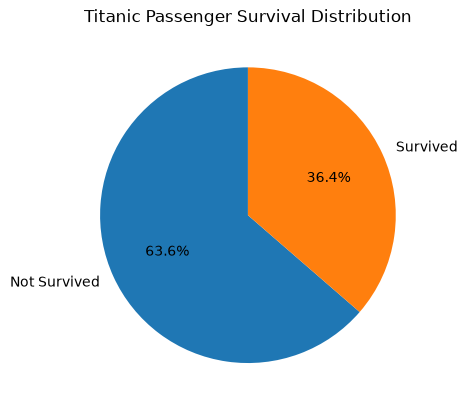

In [92]:

plt.pie(test_df['Survived'].value_counts()/len(test_df)*100, labels=['Not Survived','Survived'], autopct='%.1f%%', startangle=90)
plt.title('Titanic Passenger Survival Distribution')
plt.show()

Assignment 2 — Gender survival analysis
Real-world business question
Management wants to know:

"Were female passengers more likely to survive than male passengers?"

Your deliverables:
1. Calculate survival percentage for each gender.
2. Create a bar chart comparing the percentages.
3. Write a 2–3 sentence business insight.

In [93]:
test_df.groupby('Sex')['Survived'].mean() * 100


Sex
female    100.0
male        0.0
Name: Survived, dtype: float64

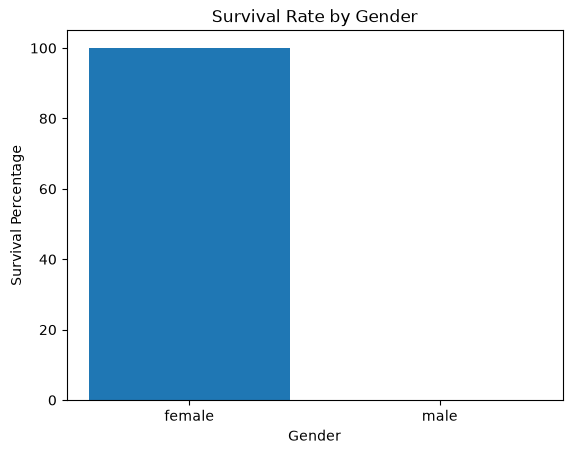

In [94]:
plt.bar(test_df.groupby('Sex')['Survived'].mean().index, test_df.groupby('Sex')['Survived'].mean()*100)
plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Percentage')
plt.show()

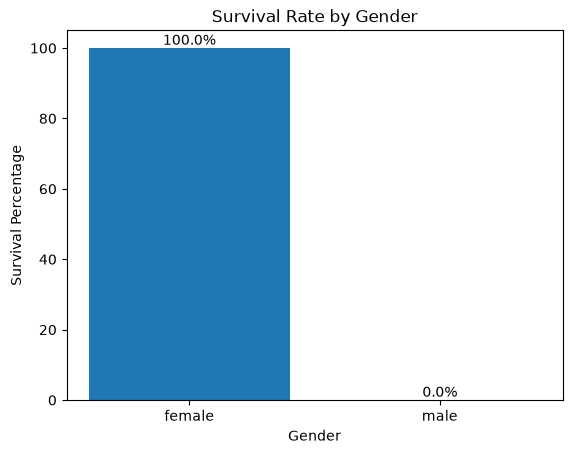

In [95]:
plt.bar_label(plt.bar(test_df.groupby('Sex')['Survived'].mean().index, test_df.groupby('Sex')['Survived'].mean()*100), labels=[f'{x:.1f}%' for x in test_df.groupby('Sex')['Survived'].mean()*100])

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Percentage')
plt.show()

Assignment 3: Passenger class survival analysis

Management wants to know which passenger class had the highest survival rate.

Your next task is to calculate the survival percentage for each Pclass using test_df.

In [96]:
test_df.groupby('Pclass')['Survived'].mean()*100

Pclass
1    46.728972
2    32.258065
3    33.027523
Name: Survived, dtype: float64

Create a professional bar chart
Requirements:
- X-axis: Passenger class
- Y-axis: Survival percentage
- Title: Survival Rate by Passenger Class
- Add percentage labels above each bar.
- Use plt.bar().

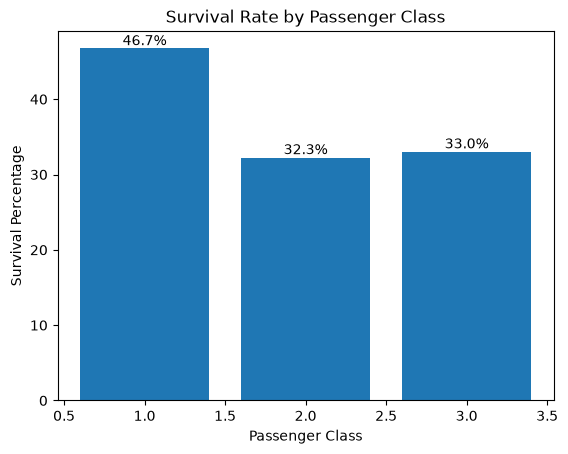

In [97]:
plt.bar_label(plt.bar(test_df.groupby('Pclass')['Survived'].mean().index, test_df.groupby('Pclass')['Survived'].mean()*100), labels=[f'{x:.1f}%' for x in test_df.groupby('Pclass')['Survived'].mean()*100])
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Percentage')
plt.show()

Assignment 4 — Age group survival analysis
Management question: Which age group had the highest survival rate?

Your task:
1. Create age groups:
   - Child: 0–12
   - Teenager: 13–19
   - Adult: 20–59
   - Senior: 60+
2. Calculate survival percentage for each group.
3. Create a bar chart with percentage labels.
4. Write a short business insight.
Start with Task 1 only: Create a new column called Age_Group in test_df.

In [98]:
test_df['Age_Group']=pd.cut(test_df['Age'], bins=[0, 12, 18, 35, 60, 100], labels=['Child', 'Teen', 'Adult', 'Middle-aged', 'Senior'])

In [99]:
test_df['Age_Group'].value_counts()/len(test_df)*100

Age_Group
Adult          61.961722
Middle-aged    22.488038
Teen            6.937799
Child           5.980861
Senior          2.631579
Name: count, dtype: float64

In [100]:
test_df.groupby('Age_Group')['Survived'].mean()*100

Age_Group
Child          48.000000
Teen           41.379310
Adult          33.590734
Middle-aged    39.361702
Senior         36.363636
Name: Survived, dtype: float64

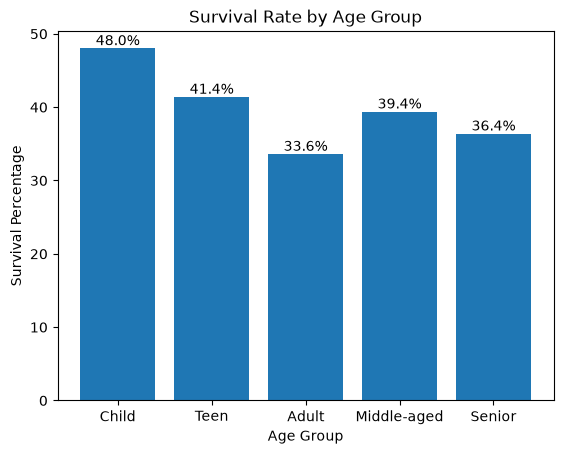

In [101]:
plt.bar_label(plt.bar(test_df.groupby('Age_Group')['Survived'].mean().index, test_df.groupby('Age_Group')['Survived'].mean()*100), labels=[f'{x:.1f}%' for x in test_df.groupby('Age_Group')['Survived'].mean()*100])
plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Percentage')
plt.show()

Assignment 5 — Family Size vs Survival
Business scenario: A travel company wants to understand whether passengers travelling with family had different survival outcomes.

Management question: Did passengers travelling alone have a different survival rate from passengers travelling with family?
Your task — Step 1 only
Create a new column named Family_Size in test_df.

Use these columns:
- SibSp — siblings and spouses aboard.
- Parch — parents and children aboard.
- Add 1 for the passenger themselves.
Your goal: Create the column and display the first 10 rows with SibSp, Parch, and Family_Size.

In [102]:
test_df['Family_Size']=test_df['SibSp']+test_df['Parch']+1

In [103]:
test_df['Family_Size']

0      1
1      2
2      1
3      1
4      3
      ..
413    1
414    1
415    1
416    1
417    3
Name: Family_Size, Length: 418, dtype: int64

Create family categories
Create a new column named Family_Category with these conditions:
- Family_Size == 1 → Alone
- Family_Size between 2 and 4 → Small Family
- Family_Size >= 5 → Large Family

In [104]:
import numpy as np
conditions = [
    test_df['Family_Size'] == 1,
    test_df['Family_Size'].between(2, 4),
    test_df['Family_Size'] >= 5
]

categories = ['Alone', 'Small Family', 'Large Family']

test_df['Family_Category'] = np.select(
    conditions,
    categories,
    default='Unknown'
)


In [105]:
test_df['Family_Category'].value_counts()

Family_Category
Alone           253
Small Family    145
Large Family     20
Name: count, dtype: int64

In [106]:
test_df['Family_Category'].value_counts()/len(test_df)*100

Family_Category
Alone           60.526316
Small Family    34.688995
Large Family     4.784689
Name: count, dtype: float64

In [107]:
test_df.groupby('Family_Category')['Survived'].mean()*100

Family_Category
Alone           26.877470
Large Family    40.000000
Small Family    52.413793
Name: Survived, dtype: float64

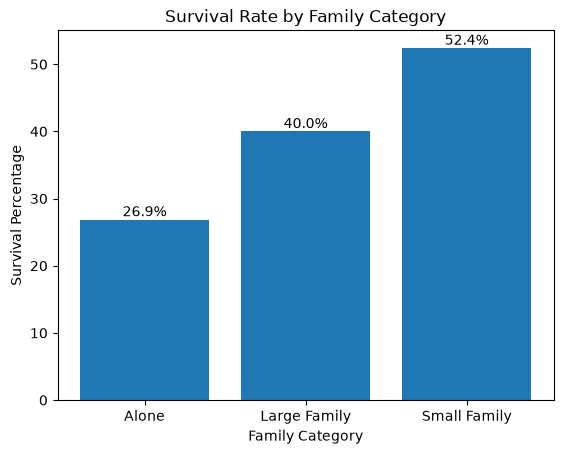

In [108]:
plt.bar_label(plt.bar(test_df.groupby('Family_Category')['Survived'].mean().index, test_df.groupby('Family_Category')['Survived'].mean()*100), labels=[f'{x:.1f}%' for x in test_df.groupby('Family_Category')['Survived'].mean()*100])
plt.title('Survival Rate by Family Category')
plt.xlabel('Family Category')
plt.ylabel('Survival Percentage')
plt.show()

Assignment 6 — Embarkation Analysis
Business question: Did the passenger's port of embarkation relate to their survival rate?

Your task — Step 1 only:

Calculate the number of passengers from each embarkation port using the Embarked column.

In [109]:
test_df['Embarked'].value_counts()

Embarked
S    270
C    102
Q     46
Name: count, dtype: int64

In [110]:
test_df.groupby('Embarked')['Survived'].mean()*100

Embarked
C    39.215686
Q    52.173913
S    32.592593
Name: Survived, dtype: float64

Step 3 — Create a bar chart
Create a bar chart showing survival rate by embarkation port.

Requirements:
- X-axis: Embarkation Port
- Y-axis: Survival Percentage
- Title: Survival Rate by Embarkation Port
- Display percentage labels above each bar.

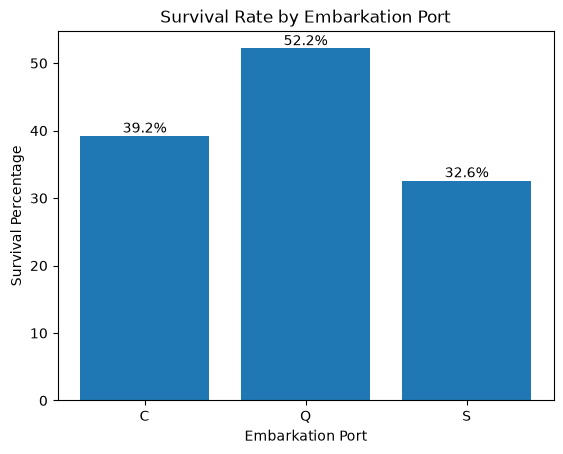

In [111]:
plt.bar_label(plt.bar(test_df.groupby('Embarked')['Survived'].mean().index, test_df.groupby('Embarked')['Survived'].mean()*100), labels=[f'{x:.1f}%' for x in test_df.groupby('Embarked')['Survived'].mean()*100])
plt.title('Survival Rate by Embarkation Port')
plt.xlabel('Embarkation Port')
plt.ylabel('Survival Percentage')
plt.show()

Assignment 7 — Final Business Insights
Now we'll turn your analysis into a professional project report.

Your first task: Write down your three most important findings from the Titanic analysis:
1. One finding about gender.
2. One finding about passenger class.
3. One finding about family size.

# Titanic Exploratory Data Analysis (EDA)

##Project Introduction

## Project Introduction

The Titanic dataset contains information about passengers aboard the RMS Titanic, including their age, gender, passenger class, family details, fare, embarkation port, and survival status.

The objective of this project is to perform Exploratory Data Analysis (EDA) to understand passenger survival patterns and identify relationships between survival and different passenger characteristics.

The analysis focuses on:
- Survival distribution among passengers.
- Survival rates based on gender and passenger class.
- Survival patterns across different age groups.
- The relationship between family size and survival.
- Survival rates based on embarkation port.

**Libraries Used:**
- **NumPy:** Numerical operations and data calculations.
- **Pandas:** Data loading, cleaning, manipulation, and analysis.
- **Matplotlib:** Creating charts and visualisations.
- **Seaborn:** Statistical data visualisation.

## Dataset Overview

The analysis was performed using the tested.csv dataset, which contains 418 rows and 12 columns. Each row represents an individual passenger, while each column represents a passenger attribute, such as age, gender, passenger class, fare, family details, and survival status."

## Data Cleaning


During the data-cleaning process, I identified and handled missing values in the dataset.

1. **Age:** Identified missing values using the `isnull()` method and replaced them with the median age.
2. **Fare:** Identified missing values and replaced them with the median fare.
3. **Cabin:** Replaced missing values with the category `"Unknown"` to retain the records.

After handling missing values, I checked for duplicate records to ensure data consistency.

## Exploratory Data Analysis




During the EDA process, I analysed different passenger attributes to identify useful patterns and understand survival trends.

1. **Survived:** Analysed the overall survival distribution and calculated the percentage of passengers who survived and did not survive.

2. **Sex:** Compared survival rates between male and female passengers. In this dataset, female passengers had a 100% survival rate, while male passengers had a 0% survival rate.

3. **Pclass:** Compared survival rates across first, second, and third passenger classes. First-class passengers had the highest survival rate at 46.73%.

4. **Age:** Analysed passenger age distribution and compared survival rates across different age groups.

5. **Fare:** Examined ticket-fare distribution and compared average fares between passengers who survived and those who did not.

## Data Visualisation



I used Matplotlib and Seaborn to create different visualisations and understand patterns in the Titanic dataset.

1. **Count Plot:** Used to compare passenger counts, including survival counts by gender and passenger class.
2. **Bar Chart:** Used to compare survival percentages across gender, passenger class, family category, and embarkation port.
3. **Histogram:** Used to understand the distribution of passenger ages and ticket fares.
4. **Box Plot:** Used to compare age distributions between passengers who survived and those who did not.
5. **Pie Chart:** Used to represent the percentage distribution of surviving and non-surviving passengers.

## Project Conclusion

Through Exploratory Data Analysis of the Titanic dataset, I identified several patterns related to passenger survival.

- Female passengers had a higher survival rate than male passengers in the analysed dataset.
- First-class passengers had the highest survival rate among the three passenger classes.
- Passengers travelling with small families had a higher survival rate than passengers travelling alone.
- Survival rates also varied across age groups and embarkation ports.

This project helped me gain practical experience in data cleaning, data manipulation, exploratory data analysis, and data visualisation using Python libraries such as NumPy, Pandas, Matplotlib, and Seaborn.

**Limitation:** The analysis is based on 418 records from `tested.csv`, so these findings should not be generalised to the entire Titanic passenger population.